# ARTI 403 Image Processing
## Lab 10: Image Segmentation and Feature Extraction

Name: Mohammed Saeed Alamodi
ID: 2240009007

The images come from skimage (camera, checkerboard and coins), so there are no image files to include.

## Task 1: Canny Edge Detection

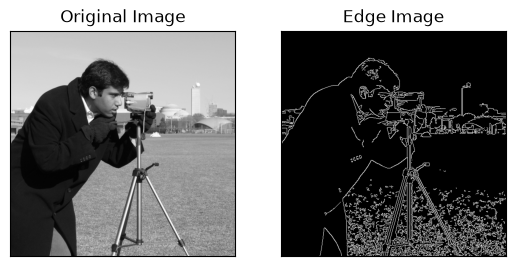

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

img = data.camera()

edges = cv2.Canny(img, 100, 200)

plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(edges, cmap='gray')
plt.title('Edge Image'), plt.xticks([]), plt.yticks([])
plt.show()

Canny gives thin, connected edges: the outline of the man, the tripod and the buildings. The flat areas like the sky stay black.

## Task 2: Harris Corner Detection

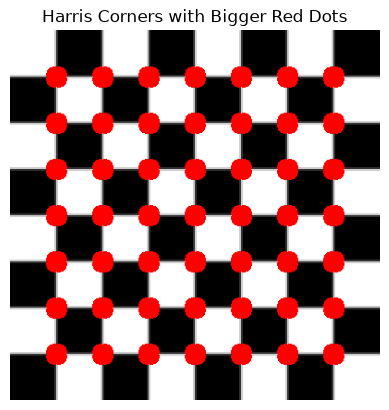

In [2]:
board = data.checkerboard()
image = cv2.cvtColor(board, cv2.COLOR_GRAY2BGR)
image = cv2.resize(image, (400, 400), interpolation=cv2.INTER_NEAREST)

# Convert to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
gray = np.float32(gray)

# Harris Corner Detection
harris = cv2.cornerHarris(gray, blockSize=2, ksize=3, k=0.04)
harris = cv2.dilate(harris, None)   # to mark corners more clearly

# Threshold for detecting strong corners
threshold = 0.01 * harris.max()
corner_coords = np.argwhere(harris > threshold)

# Draw larger red dots (radius = 7), (0, 0, 255) is red in BGR
for y, x in corner_coords:
    cv2.circle(image, (x, y), radius=7, color=(0, 0, 255), thickness=-1)

# Display
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title('Harris Corners with Bigger Red Dots')
plt.axis('off')
plt.show()

The red dots sit on the points where the black and white squares meet, which are the corners of the checkerboard. Along the straight edges between squares there are no dots.

## Simple Binary Thresholding

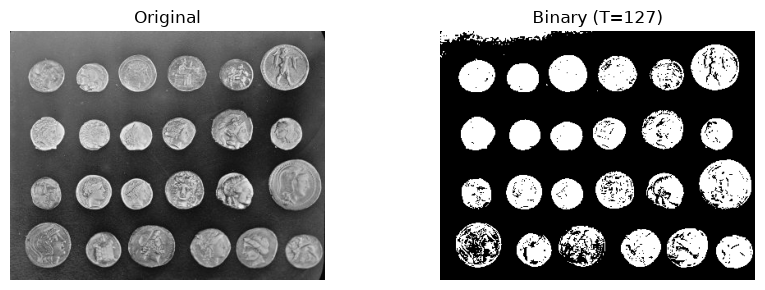

In [3]:
img = data.coins()

T = 127
_, binary = cv2.threshold(img, T, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(9, 3))
plt.subplot(1, 2, 1), plt.imshow(img, cmap='gray'), plt.title('Original'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(binary, cmap='gray'), plt.title(f'Binary (T={T})'), plt.axis('off')
plt.tight_layout()
plt.show()

# Assessment

## Q1: Otsu's Thresholding
Show the original image, its histogram and the thresholded image.

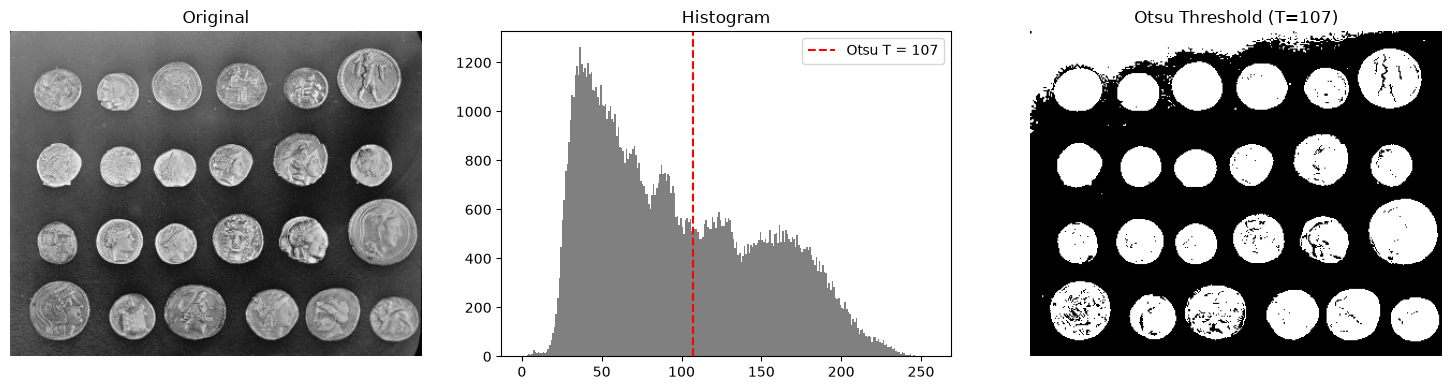

Otsu threshold: 107.0


In [4]:
img = data.coins()

# Otsu picks the threshold itself, so the T given here (0) is ignored
T_otsu, otsu = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1), plt.imshow(img, cmap='gray'), plt.title('Original'), plt.axis('off')

plt.subplot(1, 3, 2)
plt.hist(img.ravel(), bins=256, range=(0, 256), color='gray')
plt.axvline(T_otsu, color='red', linestyle='--', label=f'Otsu T = {T_otsu:.0f}')
plt.title('Histogram'), plt.legend()

plt.subplot(1, 3, 3), plt.imshow(otsu, cmap='gray'), plt.title(f'Otsu Threshold (T={T_otsu:.0f})'), plt.axis('off')
plt.tight_layout()
plt.show()

print('Otsu threshold:', T_otsu)

Otsu chose T = 107 by itself. The histogram is not a clean two peak shape, so the result is not perfect. Most coins come out white on a black background, but the lighting is uneven and the top left corner of the background turned white too. Some coins also have black spots where their surface is dark.